# Pilot Parameter Sweep

**Eval plan Step 3** — Empirically select parameter regimes where H1 is clearly observable.

**H1**: Adaptive TCT users survive significantly more rounds than Standard IDP users before budget exhaustion.

## Sweep design

Grid search over (ε, δ, target_hit_rate, population) using the same simulation code as notebook 08 (full participation, no interleaving — simplest setting, maximum discriminating power). For each combination:

- **`half_life_ratio`** = TCT_hl / IDP_hl — how many times longer TCT users survive (primary criterion)
- **`half_life_gap`** = TCT_hl − IDP_hl — absolute advantage in rounds
- **`k1_frac`** = K₁·ε / EPS_BUDGET — fraction of budget consumed at registration alone

## Selection criteria (viability)

| Criterion | Threshold | Rationale |
|---|---|---|
| `half_life_ratio` | ≥ 3 | TCT lasts ≥ 3× longer — visually compelling |
| `k1_frac` | ≤ 0.35 | Registration ≤ 35% of budget — TCT advantage is not front-loading |
| IDP half-life | ∈ [50, N_ROUNDS−50] | IDP depletes visibly but not instantly |

**Note on saturation:** TCT users may survive the full N_ROUNDS without depleting — this is a *positive* result (TCT advantage is "at least N_ROUNDS/IDP_hl"). Saturated settings are flagged `(sat)` and `half_life_ratio` is a lower bound on the true advantage.

In [1]:
import sys
sys.path.insert(0, '..')

import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_dp import StandardDPAccountant
from simulation.calibration import q_from_epsilon
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.query import compute_round_conversions, laplace_threshold_query

plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'legend.fontsize': 8.5,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'lines.linewidth': 2.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

TCT_COLOR = '#2166ac'
IDP_COLOR = '#d6604d'

In [2]:
# ── Fixed simulation parameters ──────────────────────────────────────────────
N_USERS      = 300
N_ROUNDS     = 800    # long enough to observe TCT depletion or confirm saturation
EPS_BUDGET   = 1.0
N_PILOT      = 2000
SEED         = 42

# ── Sweep axes ────────────────────────────────────────────────────────────────
EPSILONS  = [0.005, 0.01, 0.02]        # realistic attribution-DP range
DELTAS    = [1e-2, 1e-3]
HIT_RATES = [0.02, 0.05, 0.10]         # target_hit_rate; must satisfy hr << q
POPS = [
    {'name': 'MODERATE', 'alpha': 0.5, 'beta': 2.0},  # E[rate] ≈ 0.200
    {'name': 'SPARSE',   'alpha': 0.3, 'beta': 3.0},  # E[rate] ≈ 0.091
]

n_total = len(EPSILONS) * len(DELTAS) * len(HIT_RATES) * len(POPS)
print(f'Sweep: {len(EPSILONS)} ε  ×  {len(DELTAS)} δ  ×  {len(HIT_RATES)} hit_rates  '
      f'×  {len(POPS)} pops  =  {n_total} combinations')
print(f'N_USERS={N_USERS}, N_ROUNDS={N_ROUNDS}, EPS_BUDGET={EPS_BUDGET}')
print()
print(f"{'ε':>6}  {'q':>6}  {'IDP_hl':>7}  {'K₁ (δ=1e-2)':>12}  {'K₁·ε':>7}  {'k1_frac':>8}")
print('─' * 56)
for eps in EPSILONS:
    q_val = q_from_epsilon(eps)
    k1    = AdaptiveTCTAccountant(eps, 1e-2).compositions(1)
    print(f"  {eps:.3f}  {q_val:.4f}  {EPS_BUDGET/eps:7.0f}  "
          f"{k1:12.1f}  {k1*eps:7.3f}  {k1*eps/EPS_BUDGET:8.3f}")

Sweep: 3 ε  ×  2 δ  ×  3 hit_rates  ×  2 pops  =  36 combinations
N_USERS=300, N_ROUNDS=800, EPS_BUDGET=1.0

     ε       q   IDP_hl   K₁ (δ=1e-2)     K₁·ε   k1_frac
────────────────────────────────────────────────────────
  0.005  0.4988      200          24.3    0.122     0.122
  0.010  0.4975      100          24.4    0.244     0.244
  0.020  0.4950       50          24.5    0.490     0.490


In [3]:
# ── Threshold calibration (full participation) ────────────────────────────────
def calibrate_threshold(pop_cfg, epsilon, target_hit_rate, seed=SEED):
    """Find T such that the empirical noisy hit rate ≈ target_hit_rate."""
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    noisy_counts = np.empty(N_PILOT)
    for i in range(N_PILOT):
        cnt, _ = compute_round_conversions(list(pop.active_users), rng)
        noisy_counts[i] = cnt + rng.laplace(0.0, 1.0 / epsilon)
    T = float(np.quantile(noisy_counts, 1.0 - target_hit_rate))
    return T, float(np.mean(noisy_counts >= T))


# ── Simulation loop (mirrors notebook 08, full participation, no interleaving) ─
def run_simulation(accountant_factory, pop_cfg, epsilon, threshold, seed=SEED):
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    acc = accountant_factory()
    active_frac, avg_budget = [], []

    for r in range(N_ROUNDS):
        active = pop.active_users
        if not active:
            break
        parts = list(active)
        cnt, contributions = compute_round_conversions(parts, rng)
        is_top, _ = laplace_threshold_query(cnt, threshold, epsilon, rng)
        for i, user in enumerate(parts):
            e, d = acc.charge(user=user, is_top=is_top,
                              contributed=contributions[i], round_num=r)
            user.epsilon_spent += e
            user.delta_spent   += d
        pop.drop_depleted()
        eps_dist = pop.epsilon_remaining_distribution()
        active_frac.append(pop.active_fraction)
        avg_budget.append(float(np.mean(eps_dist)) if eps_dist else 0.0)

    return active_frac, avg_budget


def half_life(active_frac, threshold=0.5):
    for r, f in enumerate(active_frac):
        if f <= threshold:
            return r
    return len(active_frac)

## Section 1: Run Sweep

For each (ε, δ, hit_rate, population) combination: calibrate threshold → run Adaptive TCT and Standard IDP for N_ROUNDS rounds. Full participation only.

Output legend: `✓` = passes all viability criteria, `~` = ratio ≥ 2× but not fully viable, `(sat)` = TCT never depleted within N_ROUNDS.

In [4]:
def run_combo(epsilon, delta, target_hit_rate, alpha, beta, seed=SEED):
    cfg = PopulationConfig(
        n_users=N_USERS, alpha=alpha, beta=beta,
        epsilon_budget=EPS_BUDGET, delta_budget=1.0,
    )
    threshold, actual_hr = calibrate_threshold(cfg, epsilon, target_hit_rate, seed)

    tct_frac, tct_budget = run_simulation(
        lambda d=delta: AdaptiveTCTAccountant(epsilon, d, independent=True),
        cfg, epsilon, threshold, seed=seed)
    idp_frac, idp_budget = run_simulation(
        lambda: StandardDPAccountant(epsilon),
        cfg, epsilon, threshold, seed=seed)

    k1     = AdaptiveTCTAccountant(epsilon, delta).compositions(1)
    hl_tct = half_life(tct_frac)
    hl_idp = half_life(idp_frac)
    ratio  = round(hl_tct / max(hl_idp, 1), 2)
    viable = (ratio >= 3.0 and
              k1 * epsilon / EPS_BUDGET <= 0.35 and
              50 <= hl_idp <= N_ROUNDS - 50)

    return {
        'epsilon': epsilon, 'delta': delta,
        'target_hit_rate': target_hit_rate, 'actual_hit_rate': round(actual_hr, 3),
        'alpha': alpha, 'beta': beta,
        'q': round(q_from_epsilon(epsilon), 4),
        'k1': round(k1, 1),
        'k1_eps': round(k1 * epsilon, 3),
        'k1_frac': round(k1 * epsilon / EPS_BUDGET, 3),
        'idp_depletion': int(EPS_BUDGET / epsilon),
        'half_life_tct': hl_tct,
        'half_life_idp': hl_idp,
        'half_life_ratio': ratio,
        'half_life_gap': hl_tct - hl_idp,
        'tct_final_active': round(tct_frac[-1] if tct_frac else 0.0, 3),
        'idp_final_active': round(idp_frac[-1] if idp_frac else 0.0, 3),
        'saturated': hl_tct >= N_ROUNDS - 10,
        'viable': viable,
        '_tct_frac': tct_frac,
        '_idp_frac': idp_frac,
        '_tct_budget': tct_budget,
        '_idp_budget': idp_budget,
    }


print(f"Running {len(EPSILONS)*len(DELTAS)*len(HIT_RATES)*len(POPS)} combinations...\n", flush=True)
records = []
for pop in POPS:
    for eps, dlt, hr in itertools.product(EPSILONS, DELTAS, HIT_RATES):
        r = run_combo(eps, dlt, hr, pop['alpha'], pop['beta'])
        r['pop'] = pop['name']
        records.append(r)
        flag    = '✓' if r['viable'] else ('~' if r['half_life_ratio'] >= 2 else ' ')
        satflag = '(sat)' if r['saturated'] else '     '
        print(f" {flag} {pop['name']:8s} ε={eps:.3f} δ={dlt:.0e} hr={hr:.2f}  "
              f"ratio={r['half_life_ratio']:5.2f}×  gap=+{r['half_life_gap']:4d}  "
              f"K₁·ε={r['k1_eps']:.3f}  IDP_hl={r['half_life_idp']:4d}  {satflag}",
              flush=True)

df = pd.DataFrame(records)
print(f"\nDone. {len(df)} combinations.  Viable: {df['viable'].sum()}.  "
      f"Saturated: {df['saturated'].sum()}.")

Running 36 combinations...

 ✓ MODERATE ε=0.005 δ=1e-02 hr=0.02  ratio= 4.02×  gap=+ 601  K₁·ε=0.122  IDP_hl= 199  (sat)
 ✓ MODERATE ε=0.005 δ=1e-02 hr=0.05  ratio= 4.02×  gap=+ 601  K₁·ε=0.122  IDP_hl= 199  (sat)
 ✓ MODERATE ε=0.005 δ=1e-02 hr=0.10  ratio= 4.02×  gap=+ 601  K₁·ε=0.122  IDP_hl= 199  (sat)
 ✓ MODERATE ε=0.005 δ=1e-03 hr=0.02  ratio= 4.02×  gap=+ 601  K₁·ε=0.168  IDP_hl= 199  (sat)
 ✓ MODERATE ε=0.005 δ=1e-03 hr=0.05  ratio= 4.02×  gap=+ 601  K₁·ε=0.168  IDP_hl= 199  (sat)
 ✓ MODERATE ε=0.005 δ=1e-03 hr=0.10  ratio= 4.02×  gap=+ 601  K₁·ε=0.168  IDP_hl= 199  (sat)
 ✓ MODERATE ε=0.010 δ=1e-02 hr=0.02  ratio= 8.08×  gap=+ 701  K₁·ε=0.244  IDP_hl=  99  (sat)
 ✓ MODERATE ε=0.010 δ=1e-02 hr=0.05  ratio= 8.08×  gap=+ 701  K₁·ε=0.244  IDP_hl=  99  (sat)
 ✓ MODERATE ε=0.010 δ=1e-02 hr=0.10  ratio= 8.08×  gap=+ 701  K₁·ε=0.244  IDP_hl=  99  (sat)
 ✓ MODERATE ε=0.010 δ=1e-03 hr=0.02  ratio= 8.08×  gap=+ 701  K₁·ε=0.337  IDP_hl=  99  (sat)
 ✓ MODERATE ε=0.010 δ=1e-03 hr=0.05  ratio

## Section 2: Summary Table

Sorted by viability then `half_life_ratio`. `✓` = viable, `~` = marginal (ratio ≥ 2×), `(sat)` = TCT never depleted.

In [5]:
summary = df.sort_values(['viable', 'half_life_ratio'], ascending=[False, False])

print(f"{'pop':8s}  {'ε':6s}  {'δ':5s}  {'hr':5s}  {'K₁·ε':6s}  {'K₁%':5s}  "
      f"{'IDP_hl':6s}  {'TCT_hl':7s}  {'ratio':7s}  {'gap':6s}  {'sat':5s}  {'ok':3s}")
print('─' * 88)
for _, row in summary.iterrows():
    mark    = '✓' if row['viable'] else ('~' if row['half_life_ratio'] >= 2 else '')
    sat     = '(sat)' if row['saturated'] else ''
    tct_str = f"{row['half_life_tct']}+" if row['saturated'] else str(row['half_life_tct'])
    print(f"{row['pop']:8s}  {row['epsilon']:.3f}  {row['delta']:.0e}  "
          f"{row['target_hit_rate']:.2f}  {row['k1_eps']:.3f}  "
          f"{row['k1_frac']*100:4.1f}%  {row['half_life_idp']:6d}  "
          f"{tct_str:>7s}  {row['half_life_ratio']:6.2f}×  "
          f"{row['half_life_gap']:+6d}  {sat:5s}  {mark}")

pop       ε       δ      hr     K₁·ε    K₁%    IDP_hl  TCT_hl   ratio    gap     sat    ok 
────────────────────────────────────────────────────────────────────────────────────────
MODERATE  0.010  1e-02  0.02  0.244  24.4%      99     800+    8.08×    +701  (sat)  ✓
MODERATE  0.010  1e-02  0.05  0.244  24.4%      99     800+    8.08×    +701  (sat)  ✓
MODERATE  0.010  1e-02  0.10  0.244  24.4%      99     800+    8.08×    +701  (sat)  ✓
MODERATE  0.010  1e-03  0.02  0.337  33.7%      99     800+    8.08×    +701  (sat)  ✓
MODERATE  0.010  1e-03  0.05  0.337  33.7%      99     800+    8.08×    +701  (sat)  ✓
MODERATE  0.010  1e-03  0.10  0.337  33.7%      99     800+    8.08×    +701  (sat)  ✓
SPARSE    0.010  1e-02  0.02  0.244  24.4%      99     800+    8.08×    +701  (sat)  ✓
SPARSE    0.010  1e-02  0.05  0.244  24.4%      99     800+    8.08×    +701  (sat)  ✓
SPARSE    0.010  1e-02  0.10  0.244  24.4%      99     800+    8.08×    +701  (sat)  ✓
SPARSE    0.010  1e-03  0.02  0.337 

## Section 3: Phase Diagrams

`half_life_ratio` (TCT_hl / IDP_hl) as a function of (ε, hit_rate) for each (population × δ) panel. Green = large ratio, yellow/red = small ratio. **Bold** values meet all viability criteria (✓).

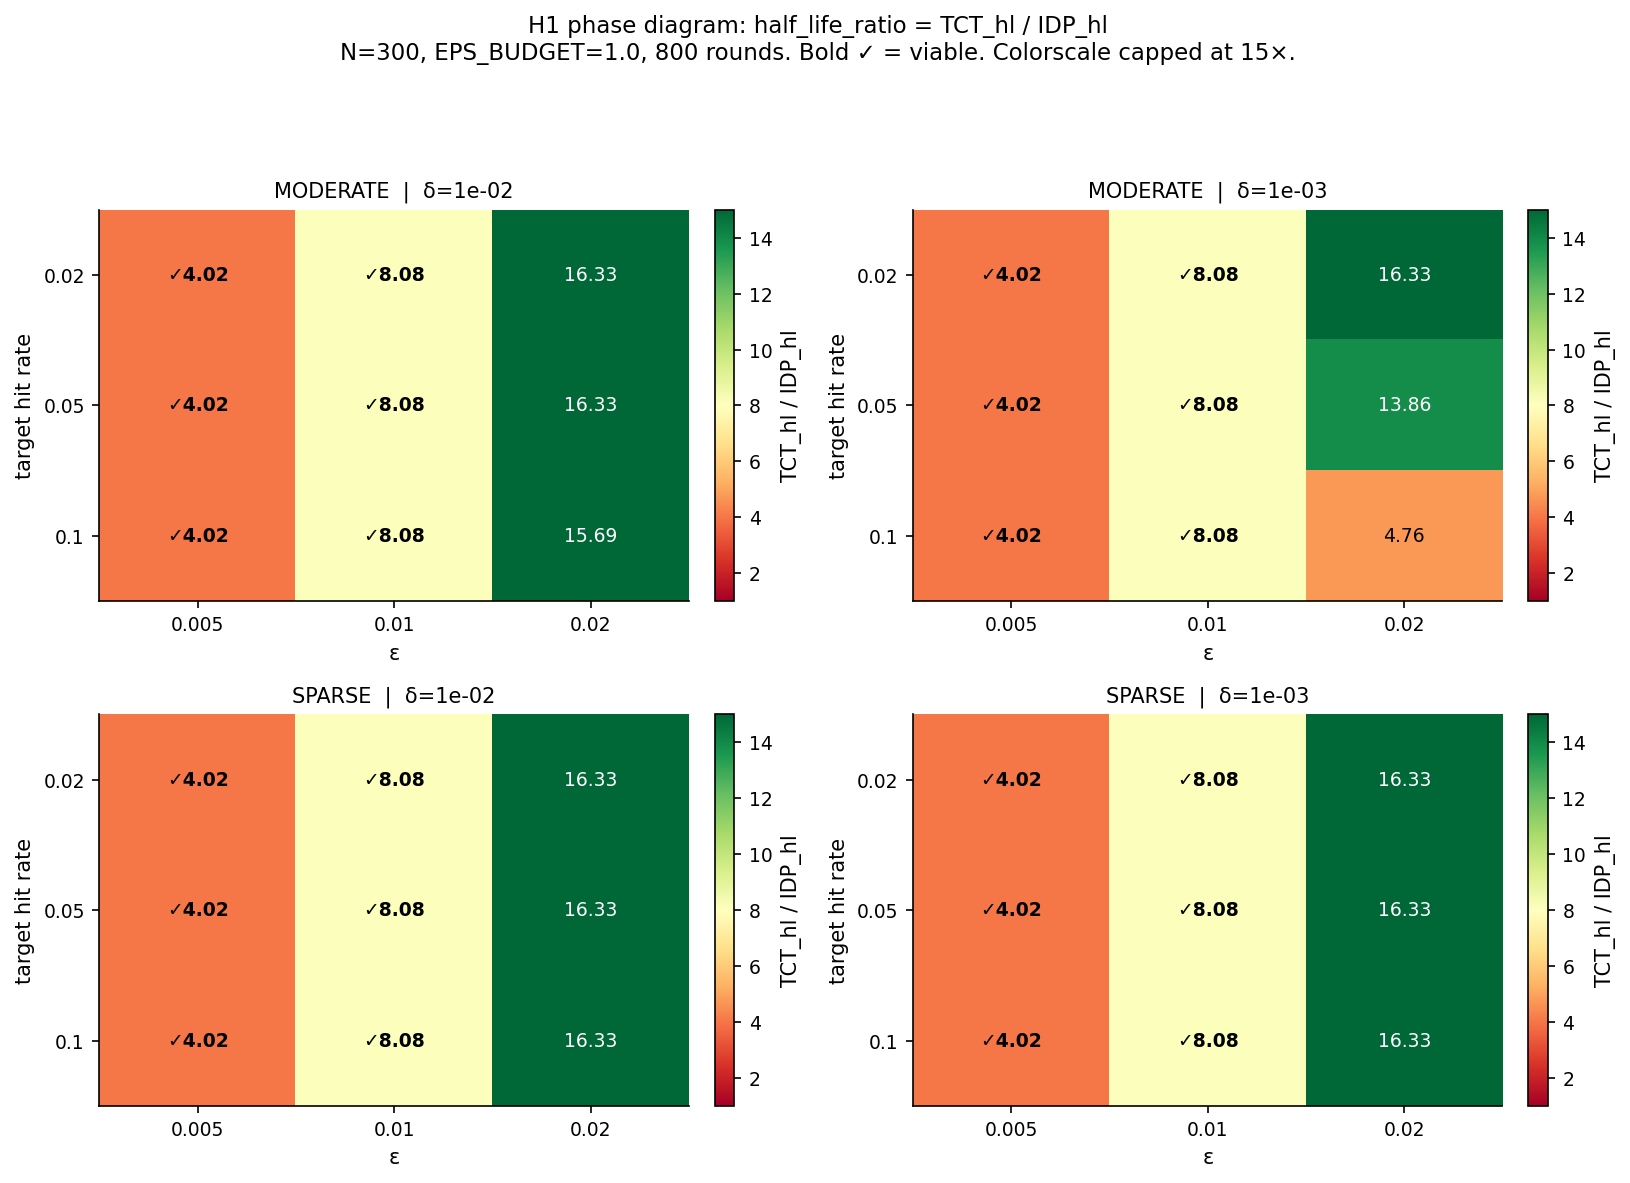

In [6]:
def make_heatmap(ax, ratio_pivot, viable_pivot, title):
    data   = ratio_pivot.values.astype(float)
    viable = viable_pivot.values.astype(bool)
    v_hi   = min(float(data.max()), 15.0)  # cap colorscale at 15× to avoid washout
    im = ax.imshow(data, cmap='RdYlGn', vmin=1.0, vmax=v_hi, aspect='auto')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='TCT_hl / IDP_hl')
    ax.set_xticks(range(len(ratio_pivot.columns)))
    ax.set_xticklabels([str(c) for c in ratio_pivot.columns])
    ax.set_yticks(range(len(ratio_pivot.index)))
    ax.set_yticklabels([str(v) for v in ratio_pivot.index])
    ax.set_xlabel('ε')
    ax.set_ylabel('target hit rate')
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val   = data[i, j]
            color = 'white' if val > 0.65 * v_hi else 'black'
            fw    = 'bold' if viable[i, j] else 'normal'
            label = f"{'✓' if viable[i, j] else ''}{val:.2f}"
            ax.text(j, i, label, ha='center', va='center',
                    fontsize=9, color=color, fontweight=fw)
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for (row_idx, pop_name), (col_idx, dlt) in itertools.product(
    enumerate(['MODERATE', 'SPARSE']), enumerate(DELTAS)
):
    ax  = axes[row_idx][col_idx]
    sub = df[(df['pop'] == pop_name) & (df['delta'] == dlt)]
    ratio_pivot  = sub.pivot(index='target_hit_rate', columns='epsilon',
                             values='half_life_ratio')
    viable_pivot = sub.pivot(index='target_hit_rate', columns='epsilon',
                             values='viable')
    make_heatmap(ax, ratio_pivot, viable_pivot,
                 f'{pop_name}  |  δ={dlt:.0e}')

fig.suptitle(
    f'H1 phase diagram: half_life_ratio = TCT_hl / IDP_hl\n'
    f'N={N_USERS}, EPS_BUDGET={EPS_BUDGET}, {N_ROUNDS} rounds. '
    f'Bold ✓ = viable. Colorscale capped at 15×.',
    fontsize=11,
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig('../figures/pilot_phase_diagram.png', bbox_inches='tight', dpi=200)
plt.show()

## Section 4: Retention Curves for Top Viable Settings

Full user-retention curves for the top viable combinations (largest `half_life_ratio`). Blue = Adaptive TCT, red dashed = Standard IDP. Dotted verticals mark each method's half-life. A `+` in the TCT label means it saturated (never depleted).

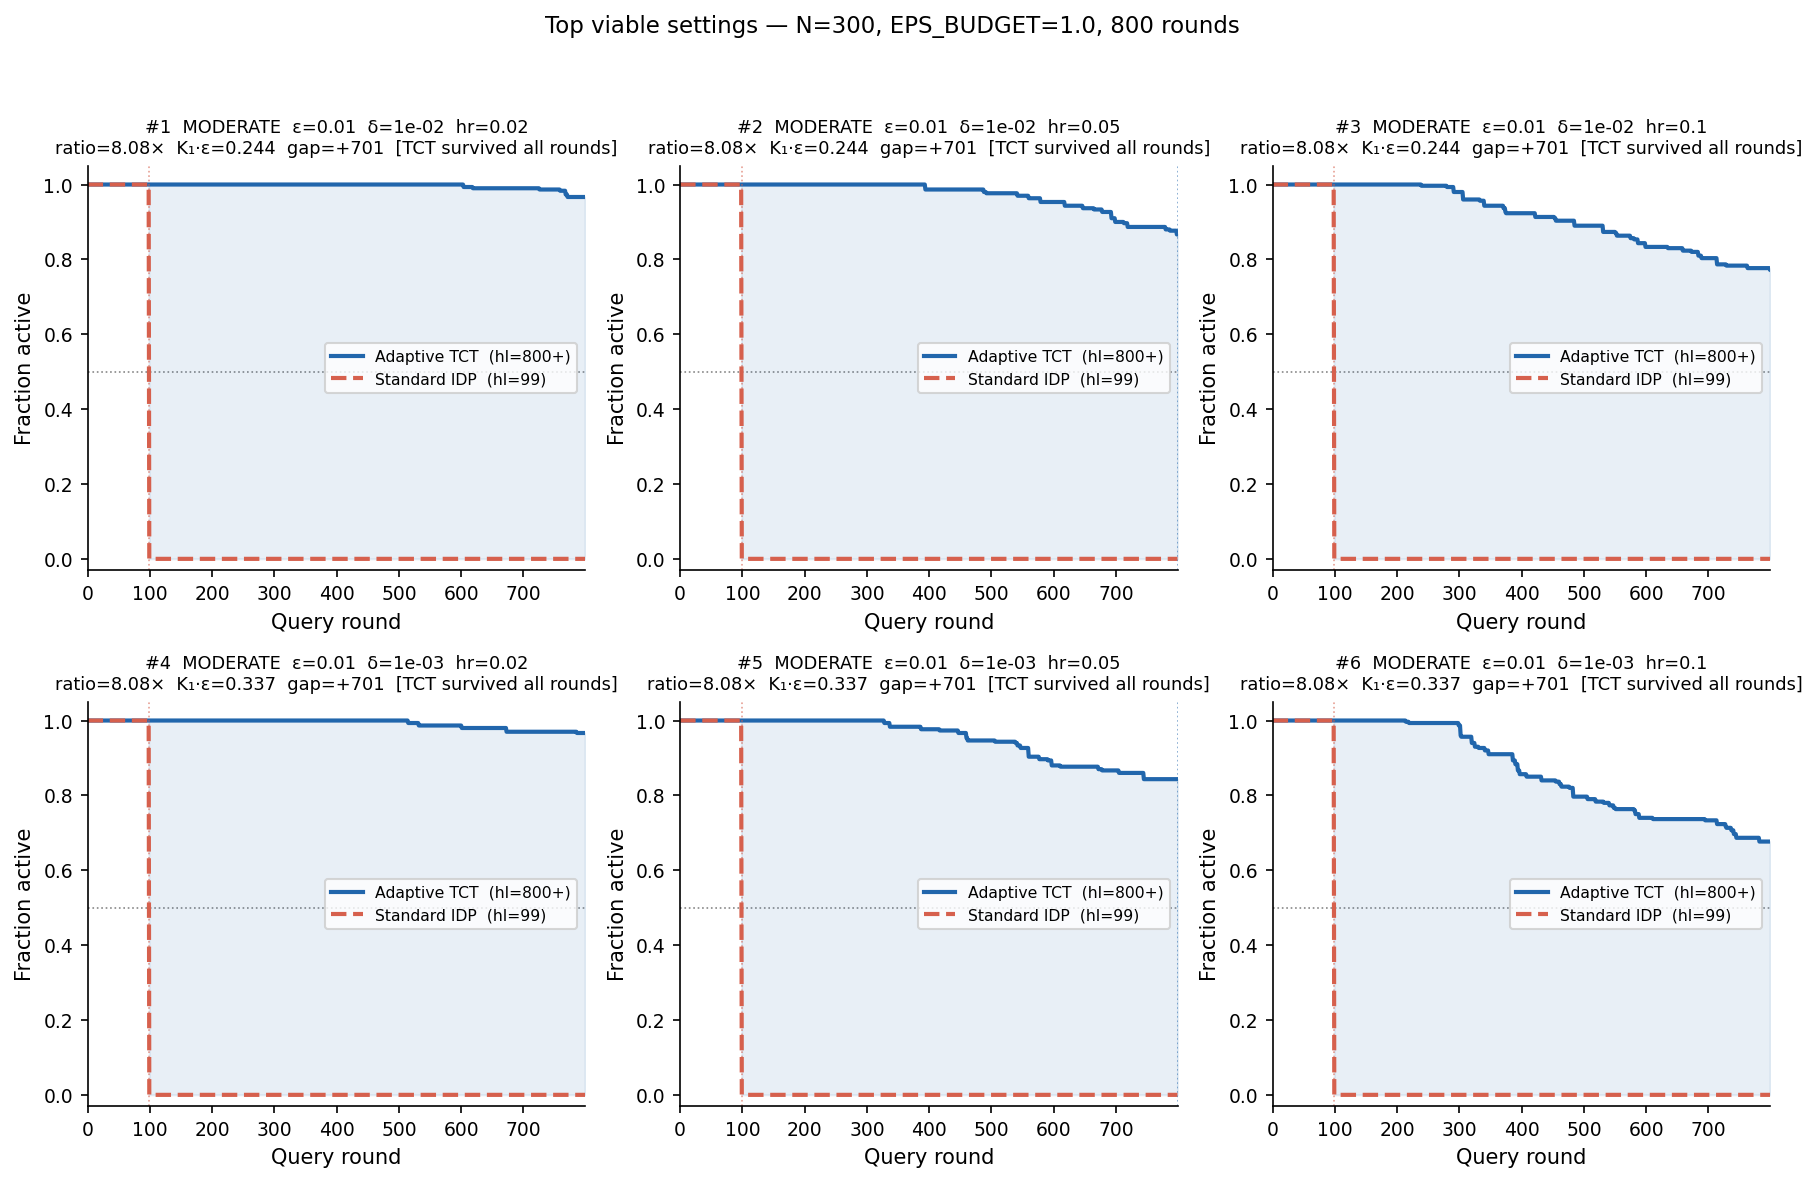

In [7]:
top = df[df['viable']].nlargest(6, 'half_life_ratio').reset_index(drop=True)
if len(top) < 3:
    print(f'Only {len(top)} viable combos — supplementing with next-best.')
    extra = (df[~df['viable']]
             .nlargest(6 - len(top), 'half_life_ratio')
             .reset_index(drop=True))
    top = pd.concat([top, extra]).reset_index(drop=True)

n_show = min(6, len(top))
ncols  = 3
nrows  = math.ceil(n_show / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes_flat = np.array(axes).reshape(-1)

for idx in range(n_show):
    ax  = axes_flat[idx]
    row = top.iloc[idx]
    tct_a = row['_tct_frac']
    idp_a = row['_idp_frac']
    n     = max(len(tct_a), len(idp_a))
    rnds  = list(range(n))
    tct_p = tct_a + [tct_a[-1]] * (n - len(tct_a))
    idp_p = idp_a + [idp_a[-1]] * (n - len(idp_a))
    hl_t  = row['half_life_tct']
    hl_i  = row['half_life_idp']
    sat   = row['saturated']

    ax.plot(rnds, tct_p, color=TCT_COLOR, lw=2,
            label=f'Adaptive TCT  (hl={hl_t}{"+" if sat else ""})')
    ax.plot(rnds, idp_p, color=IDP_COLOR, lw=2, linestyle='--',
            label=f'Standard IDP  (hl={hl_i})')
    ax.fill_between(rnds, idp_p, tct_p, alpha=0.10, color=TCT_COLOR)
    ax.axhline(0.5, color='#888', lw=0.8, linestyle=':', zorder=0)
    ax.axvline(hl_t, color=TCT_COLOR, lw=0.8, linestyle=':', alpha=0.6)
    ax.axvline(hl_i, color=IDP_COLOR,  lw=0.8, linestyle=':', alpha=0.6)
    ax.set_xlim(0, n - 1)
    ax.set_ylim(-0.03, 1.05)
    ax.set_xlabel('Query round')
    ax.set_ylabel('Fraction active')
    ax.legend(fontsize=7.5)
    sat_note = '  [TCT survived all rounds]' if sat else ''
    ax.set_title(
        f"#{idx+1}  {row['pop']}  ε={row['epsilon']}  δ={row['delta']:.0e}  "
        f"hr={row['target_hit_rate']}\n"
        f"ratio={row['half_life_ratio']:.2f}×  K₁·ε={row['k1_eps']:.3f}  "
        f"gap=+{row['half_life_gap']}{sat_note}",
        fontsize=8.5,
    )

for idx in range(n_show, len(axes_flat)):
    axes_flat[idx].set_visible(False)

fig.suptitle(f'Top viable settings — N={N_USERS}, EPS_BUDGET={EPS_BUDGET}, {N_ROUNDS} rounds',
             fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/pilot_top_settings.png', bbox_inches='tight', dpi=200)
plt.show()

## Section 5: Scientific Parameter Selection

Criteria applied in priority order:

1. **`half_life_ratio ≥ 3`** — TCT survives ≥ 3× longer (strong, visually clear)
2. **`k1_frac ≤ 0.35`** — registration cost ≤ 35% of budget (advantage is not front-loading)
3. **IDP half-life ∈ [50, N_ROUNDS−50]** — IDP depletes visibly but not instantly
4. **Not saturated** (secondary preference) — full depletion curve visible; otherwise we report a lower bound on the ratio

Among viable settings, rank by `half_life_ratio` descending, then `k1_frac` ascending (prefer conservative upfront cost).

In [ ]:
viable_ns  = df[ df['viable'] & ~df['saturated']].sort_values(
    ['half_life_ratio', 'k1_frac'], ascending=[False, True])
viable_sat = df[ df['viable'] &  df['saturated']].sort_values(
    ['half_life_ratio', 'k1_frac'], ascending=[False, True])
candidates = pd.concat([viable_ns, viable_sat]).reset_index(drop=True)

if len(candidates) == 0:
    print('No viable settings. Showing top 5 by ratio.')
    candidates = df.sort_values('half_life_ratio', ascending=False).head(5).reset_index(drop=True)

print('Viable settings for H1 (non-saturated first, then saturated):')
print('=' * 100)
print(f"{'#':>3}  {'pop':8s}  {'ε':6s}  {'δ':5s}  {'hr':5s}  "
      f"{'K₁':5s}  {'K₁·ε':6s}  {'K₁%':5s}  "
      f"{'IDP_hl':6s}  {'TCT_hl':7s}  {'ratio':7s}  {'gap':6s}  {'sat':5s}")
print('─' * 100)
for i, (_, row) in enumerate(candidates.iterrows(), 1):
    sat     = '(sat)' if row['saturated'] else ''
    tct_str = f"{row['half_life_tct']}+" if row['saturated'] else str(row['half_life_tct'])
    print(f"{i:>3}  {row['pop']:8s}  {row['epsilon']:.3f}  {row['delta']:.0e}  "
          f"{row['target_hit_rate']:.2f}  {row['k1']:5.1f}  {row['k1_eps']:.3f}  "
          f"{row['k1_frac']*100:4.1f}%  {row['half_life_idp']:6d}  "
          f"{tct_str:>7s}  {row['half_life_ratio']:6.2f}×  "
          f"{row['half_life_gap']:+6d}  {sat}")

# ── Primary recommendation ─────────────────────────────────────────────────────
print()
if len(candidates) > 0:
    best = candidates.iloc[0]
    sat_note = (' (saturated — ratio is a lower bound on true advantage)'
                if best['saturated'] else '')
    print('═' * 68)
    print('RECOMMENDED PARAMETERS FOR NOTEBOOK 08 (H1 MAIN EXPERIMENT)')
    print('═' * 68)
    print(f"  EPSILON         = {best['epsilon']}")
    print(f"  DELTA           = {best['delta']:.0e}")
    print(f"  TARGET_HIT_RATE = {best['target_hit_rate']}")
    print(f"  ALPHA_POP       = {best['alpha']}")
    print(f"  BETA_POP        = {best['beta']}")
    print(f"  Population:      {best['pop']}"
          f"  (E[rate] = {best['alpha']/(best['alpha']+best['beta']):.3f})")
    print()
    print(f"  q (Lemma 2.3):   {best['q']:.4f}  "
          f"[hit rate {best['target_hit_rate']:.2f} << q {best['q']:.4f} ✓]")
    print(f"  K₁ = {best['k1']:.1f}  →  K₁·ε = {best['k1_eps']:.3f} "
          f"({best['k1_frac']*100:.1f}% of EPS_BUDGET)")
    print(f"  IDP half-life:   {best['half_life_idp']} rounds "
          f"(= EPS_BUDGET/ε = {EPS_BUDGET/best['epsilon']:.0f} rounds ✓)")
    tct_str = f"≥ {best['half_life_tct']}" if best['saturated'] else str(best['half_life_tct'])
    print(f"  TCT half-life:   {tct_str} rounds{sat_note}")
    print(f"  Half-life ratio: ≥ {best['half_life_ratio']:.2f}×  "
          f"(TCT users survive ≥{best['half_life_ratio']:.1f}× longer than IDP)")
    print()
    print('  Suggested ROBUST_SETTINGS for notebook 08:')
    print('  ' + '─' * 55)
    for i, (_, row) in enumerate(candidates.head(3).iterrows(), 1):
        sat_flag = '(sat)' if row['saturated'] else ''
        print(f"  Setting {chr(64+i)}: ε={row['epsilon']}, δ={row['delta']:.0e}, "
              f"α={row['alpha']}, β={row['beta']}, "
              f"hr={row['target_hit_rate']}  "
              f"→ ratio={row['half_life_ratio']:.2f}×  {sat_flag}")

Viable settings for H1 (non-saturated first, then saturated):
  #  pop       ε       δ      hr     K₁     K₁·ε    K₁%    IDP_hl  TCT_hl   ratio    gap     sat  
────────────────────────────────────────────────────────────────────────────────────────────────────
  1  MODERATE  0.010  1e-02  0.02   24.4  0.244  24.4%      99     800+    8.08×    +701  (sat)
  2  MODERATE  0.010  1e-02  0.05   24.4  0.244  24.4%      99     800+    8.08×    +701  (sat)
  3  MODERATE  0.010  1e-02  0.10   24.4  0.244  24.4%      99     800+    8.08×    +701  (sat)
  4  SPARSE    0.010  1e-02  0.02   24.4  0.244  24.4%      99     800+    8.08×    +701  (sat)
  5  SPARSE    0.010  1e-02  0.05   24.4  0.244  24.4%      99     800+    8.08×    +701  (sat)
  6  SPARSE    0.010  1e-02  0.10   24.4  0.244  24.4%      99     800+    8.08×    +701  (sat)
  7  MODERATE  0.010  1e-03  0.02   33.7  0.337  33.7%      99     800+    8.08×    +701  (sat)
  8  MODERATE  0.010  1e-03  0.05   33.7  0.337  33.7%      99    